# Quick start: train a world model and plan with it

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/latent-horizon/pytorch-world/blob/main/examples/quickstart.ipynb)

A world model predicts what comes next. This notebook trains [LeWM](https://arxiv.org/abs/2603.19312) from pixels, then plans with it: it searches for the actions whose imagined future looks like a goal image. It takes a few minutes on a Colab GPU.

In [ ]:
import importlib.util

if importlib.util.find_spec("torch_world") is None:  # on Colab
    %pip install -q "torch-world[examples]"

In [2]:
import torch
from torch.utils.data import DataLoader

from torch_world import evaluation, plots
from torch_world.datasets import TrajectoryDataset
from torch_world.envs import Macaw
from torch_world.models import LeWM
from torch_world.nn import CLSEncoder
from torch_world.planning import CEM
from torch_world.utils import fit

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

## 1. Collect data
`Macaw` is a Hyacinth macaw flying over the Pantanal, steered by velocity actions. Its wings beat a quarter cycle per step. Random actions give 2048 flights of 16 frames, seen at 64×64 and cut into windows of 4.

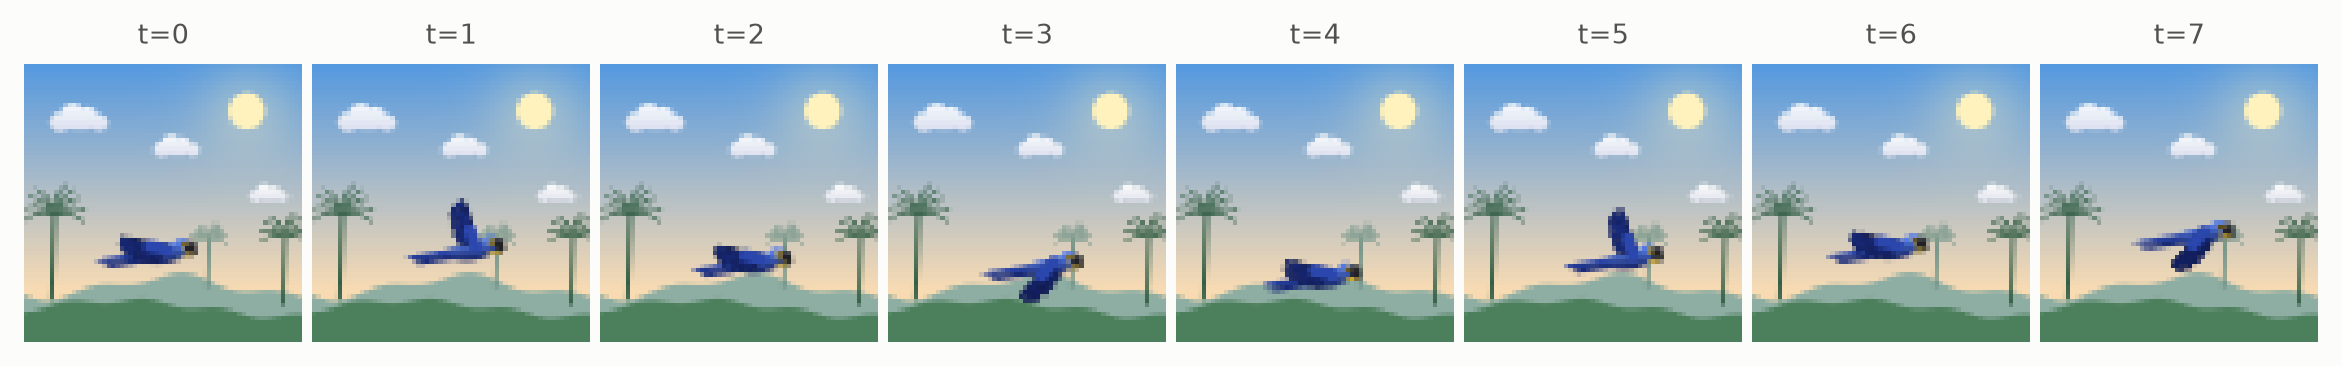

In [3]:
data = Macaw(batch_size=2048, device=device).collect(16)
loader = DataLoader(TrajectoryDataset(data, window=4), batch_size=128, shuffle=True, drop_last=True)
plots.images(data["pixels"][0, :8].cpu(), [f"t={t}" for t in range(8)], size=1.2)

## 2. Train
A small ViT embeds each frame, and a transformer predicts the next embedding from the past ones and the actions. SIGReg keeps the embeddings from collapsing.

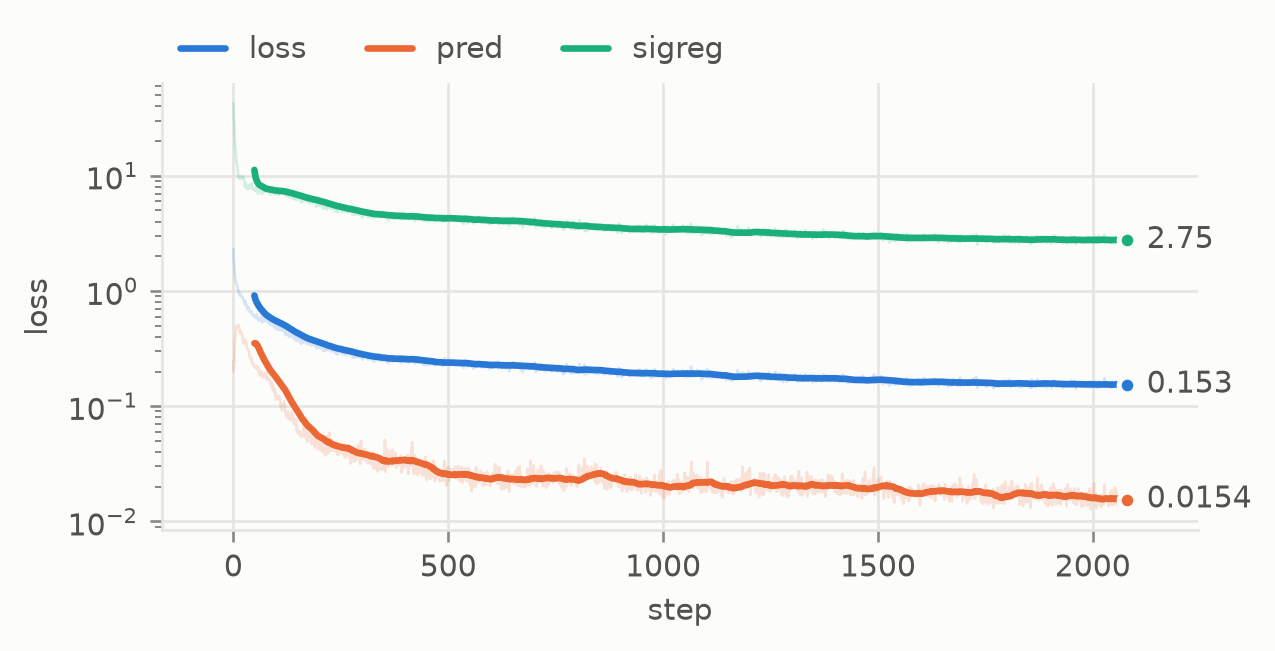

In [4]:
encoder = CLSEncoder(img_size=64, patch_size=8, embed_dim=128, depth=4, num_heads=4)
model = LeWM(encoder, action_dim=2, embed_dim=128, depth=4, num_heads=4, head_dim=32, mlp_dim=512, proj_dim=512, lamb=0.05).to(device)
log = fit(model, loader, epochs=10)
plots.curves(log, smooth=50)

## 3. Plan toward goal images
Each flight gets the image of the macaw somewhere else. CEM imagines 256 action sequences, keeps those whose imagined embeddings come closest to the goal image's, and refits; the first action runs and it plans again.

In [5]:
env = Macaw(batch_size=32, device=device)
env.reset(generator=torch.Generator().manual_seed(1))
start, goal = env.state.clone(), env.sample_goals((0.2, 0.5), generator=torch.Generator().manual_seed(2))

planner = CEM(horizon=5, action_dim=2, num_samples=256, num_elites=32, bounds=(-1, 1), objective="path")
policies = {
    "LeWM + CEM": evaluation.goal_policy(model, planner, env.render(goal)),
    "random actions": evaluation.random_policy(env),
}
video = Macaw(batch_size=32, size=192, device=device)  # the same states, drawn sharper, with the goal as a ghost
result = evaluation.goal_reaching(env, policies, start, goal, steps=20, success="reached", record=lambda e: video.render(e.state, e.phase, goal=goal))
result

                          success  reached   steps  final distance  progress     SPL  smoothness  ms / step
LeWM + CEM         69% [51%, 82%]      69%    2.36          0.0107      0.96   0.467       0.218   2.94e+03
random actions     25% [13%, 42%]      25%    10.2           0.363   -0.0639  0.0483        1.05      0.195

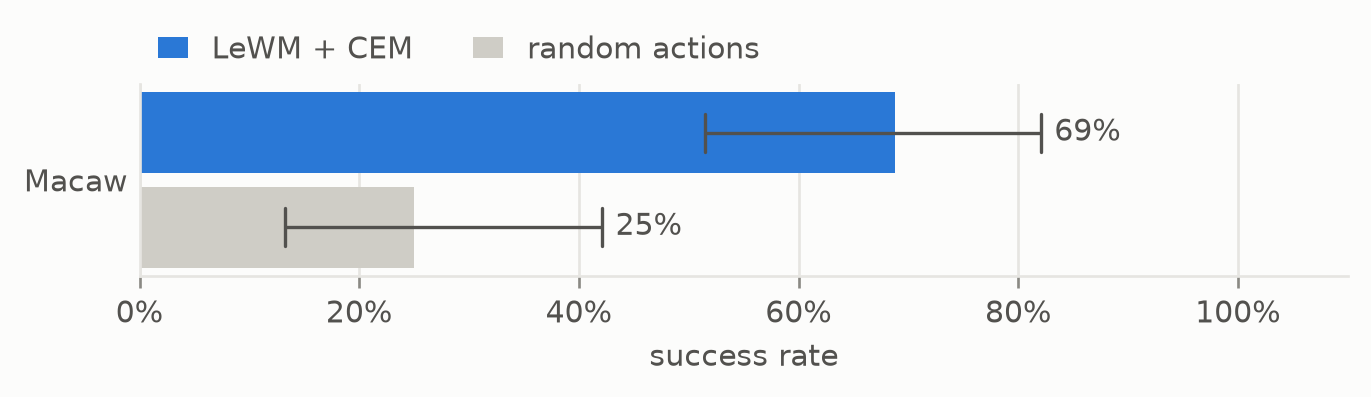

In [6]:
plots.bars({"Macaw": result.intervals()}, xlabel="success rate", baseline="random actions")

The planner's flights; the translucent macaw marks the goal (in the videos only, the model sees plain frames):


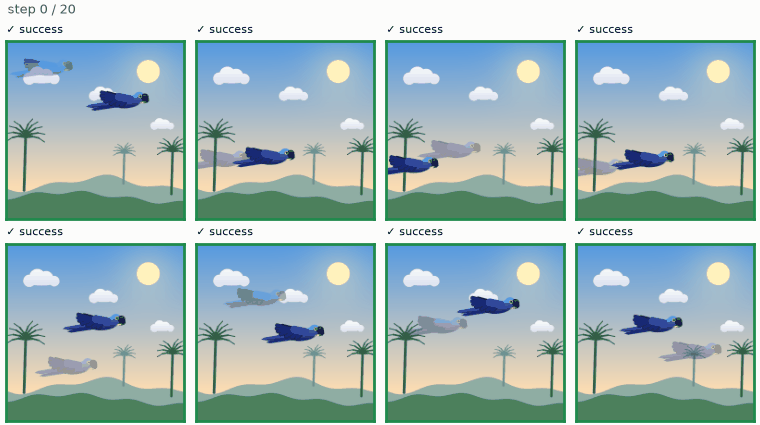

In [7]:
plots.episodes(result.frames["LeWM + CEM"][:8], result.success["LeWM + CEM"][:8])

## Next
- [Models](https://latent-horizon.github.io/pytorch-world/models/): JEPA world models, DINO-WM, TD-MPC2, PLDM, hierarchical and stochastic models, each with a notebook.
- [Comparisons](https://latent-horizon.github.io/pytorch-world/guides/results): the same tasks, models and planners side by side.
- [Build your own model](custom_model.ipynb) from the shared parts.